In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Please upload two images (e.g., image1.jpg and image2.jpg):")
uploaded = files.upload()
image_names = list(uploaded.keys())

if len(image_names) >= 2:
    img1_path = image_names[0]
    img2_path = image_names[1]
    print(f"Loaded {img1_path} and {img2_path} for matching.")
else:
    print("Please upload at least two images for feature matching.")

Please upload two images (e.g., image1.jpg and image2.jpg):


Saving test_image2.jpg to test_image2.jpg
Saving test_image.jpg to test_image (2).jpg
Loaded test_image2.jpg and test_image (2).jpg for matching.


SURF is disabled in this OpenCV build due to patent restrictions. Falling back to SIFT as per lab notes.
Number of SIFT keypoints (Image 1): 1332
Number of ORB keypoints (Image 1): 500


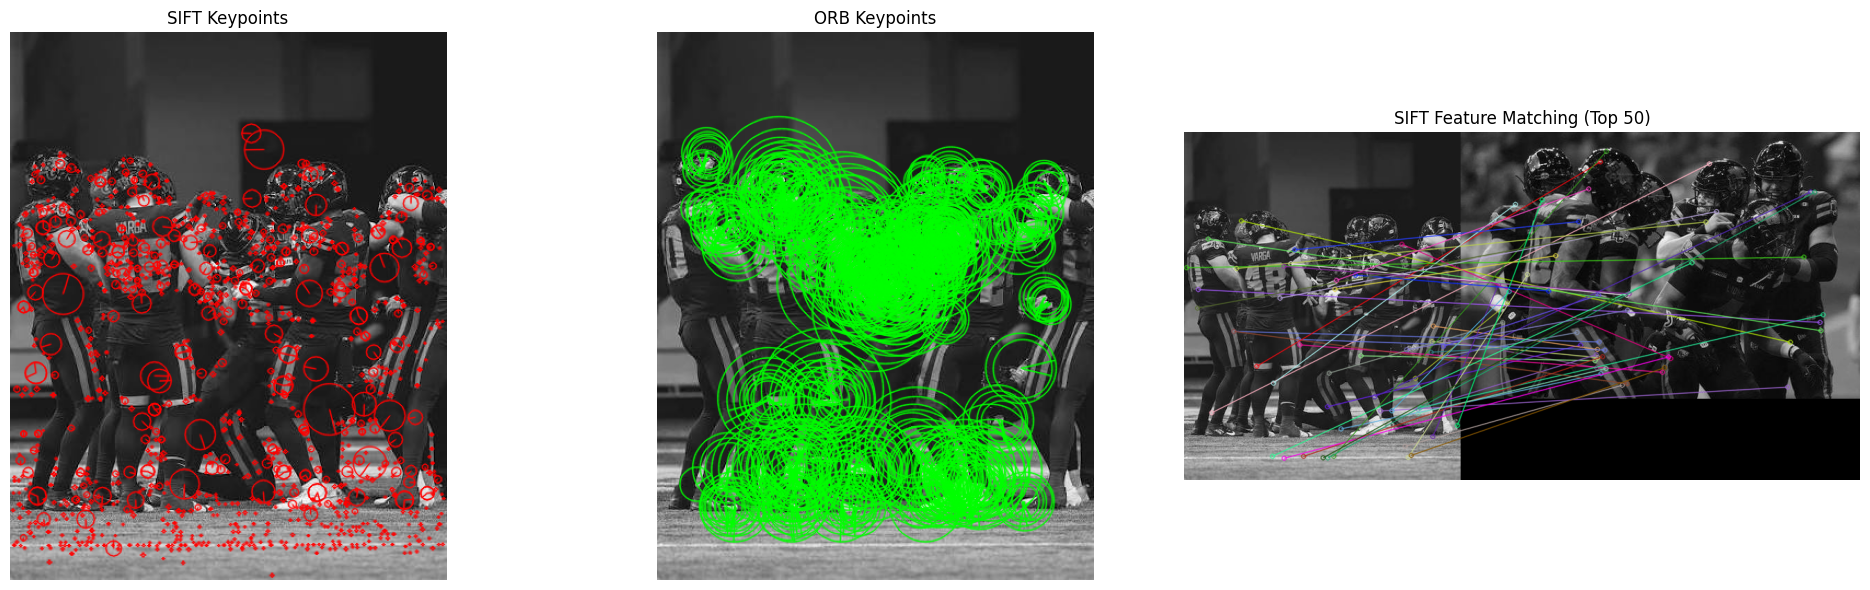

In [ ]:
img1 = cv2.imread(img1_path, cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(img2_path, cv2.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
    print('Error loading images')
else:
    # --- 1. Initialize Detectors ---

    # Try creating SURF object (Hessian threshold = 400)
    try:
        surf = cv2.xfeatures2d.SURF_create(hessianThreshold=400)
        detector_name = "SURF"
        detector = surf
    except cv2.error: # Updated to catch the specific OpenCV patent error
        print("SURF is disabled in this OpenCV build due to patent restrictions. Falling back to SIFT as per lab notes.")
        sift = cv2.SIFT_create()
        detector_name = "SIFT"
        detector = sift

    # ORB initialization for comparison
    orb = cv2.ORB_create()

    # --- 2. Detect Keypoints and Descriptors ---
    kp1_primary, des1_primary = detector.detectAndCompute(img1, None)
    kp2_primary, des2_primary = detector.detectAndCompute(img2, None)

    kp1_orb, des1_orb = orb.detectAndCompute(img1, None)

    print(f"Number of {detector_name} keypoints (Image 1): {len(kp1_primary)}")
    print(f"Number of ORB keypoints (Image 1): {len(kp1_orb)}")

    # --- 3. Draw Keypoints ---
    # Draw keypoints on the image with size and orientation information
    img1_keypoints = cv2.drawKeypoints(img1, kp1_primary, None, (255, 0, 0), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    img1_orb_keypoints = cv2.drawKeypoints(img1, kp1_orb, None, (0, 255, 0), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

    # --- 4. Feature Matching ---
    # Use Brute-Force Matcher
    bf = cv2.BFMatcher(cv2.NORM_L2 if detector_name != "ORB" else cv2.NORM_HAMMING, crossCheck=True)
    matches = bf.match(des1_primary, des2_primary)

    # Sort matches in the order of their distance
    matches = sorted(matches, key = lambda x:x.distance)

    # Draw first 50 matches
    img_matches = cv2.drawMatches(img1, kp1_primary, img2, kp2_primary, matches[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # --- 5. Visualization ---
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    axs[0].imshow(img1_keypoints)
    axs[0].set_title(f'{detector_name} Keypoints')
    axs[0].axis('off')

    axs[1].imshow(img1_orb_keypoints)
    axs[1].set_title('ORB Keypoints')
    axs[1].axis('off')

    axs[2].imshow(img_matches)
    axs[2].set_title(f'{detector_name} Feature Matching (Top 50)')
    axs[2].axis('off')

    plt.tight_layout()
    plt.show()